# Triage + Caregiver Matching — End-to-End (TF-IDF + Logistic Regression, rule-based matcher, FastAPI)

**Is notebook mein kya hai**

| Part | Kya banta hai | Output |
|---|---|---|
| 1 | Data load + EDA (`triage_dataset_flat.csv`, `caregivers.csv`) | insights |
| 2 | TF-IDF (word + char n-gram) + Logistic Regression, **group-wise CV** | metrics, confusion matrix |
| 3 | Final fit + **saved pipelines** | `artifacts/care_type_pipeline.pkl`, `artifacts/urgency_pipeline.pkl`, `artifacts/model_meta.json` |
| 4 | Safety rules (red-flag), language detection, follow-up question | `triage_logic.py` |
| 5 | **Rule-based matching/ranking** (caregiver CSV se, ML nahi) | `matcher.py` |
| 6 | Dono ko jodta **FastAPI** service | `app.py` (+ `TestClient` se test) |

**Design rule:** `.pkl` sirf *model artifact* hai (TF-IDF + LR). Matching alag rule-based module hai jo caregiver CSV se chalta hai — dono sirf FastAPI mein connect hote hain.

```
user text ──► triage_logic.triage()  ──► care_type / urgency / red_flags / follow-up
                 (rules + .pkl models)            │
                                                  ▼ (sirf agar care_type matchable ho)
lat,lng,time ─────────────────────────► matcher.match_caregivers()  ──► top-K caregivers
                                          (caregivers.csv, rules)
```

> Python code ke `%%writefile` cells project folder mein real `.py` files banate hain, aur wahi files neeche test hoti hain — yaani jo test hua wahi ship hota hai.

## 1. Setup

In [1]:
import json, re, sys, shutil, importlib, warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import sklearn

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit, KFold, cross_val_predict
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)

SEED = 42
BASE = Path.cwd()
DATA_DIR, ART_DIR = BASE / "data", BASE / "artifacts"
DATA_DIR.mkdir(exist_ok=True); ART_DIR.mkdir(exist_ok=True)

# CSVs ko ./data mein dhoondho (notebook ke saath, ./data mein, ya upload folder mein)
for name in ["triage_dataset_flat.csv", "caregivers.csv"]:
    if not (DATA_DIR / name).exists():
        for cand in [BASE / name, Path("/mnt/user-data/uploads") / name]:
            if cand.exists():
                shutil.copy(cand, DATA_DIR / name); break
        else:
            raise FileNotFoundError(f"{name} ko notebook ke folder ya ./data mein rakhein")

print("sklearn", sklearn.__version__, "| pandas", pd.__version__)
print("data :", sorted(p.name for p in DATA_DIR.iterdir()))

sklearn 1.9.1 | pandas 3.0.5
data : ['caregivers.csv', 'triage_dataset_flat.csv']


## 2. Data load + EDA

In [2]:
triage = pd.read_csv(DATA_DIR / "triage_dataset_flat.csv")
caregivers_raw = pd.read_csv(DATA_DIR / "caregivers.csv")

print("triage:", triage.shape, "| caregivers:", caregivers_raw.shape)
print("\nUnique user_input texts:", triage.user_input.nunique(), "of", len(triage), "rows")
display(triage.care_type.value_counts(dropna=False).to_frame("rows").join(
        triage.groupby(triage.care_type.fillna("NaN")).user_input.nunique().rename("unique_texts"), how="left"))
display(pd.crosstab(triage.care_type.fillna("NaN (needs follow-up)"), triage.detected_language))
display(pd.crosstab(triage.care_type.fillna("NaN"), triage.urgency.fillna("NaN")))

triage: (340, 12) | caregivers: (60, 17)

Unique user_input texts: 66 of 340 rows


,rows,unique_texts
care_type,,
home_nursing,103,18.0
emergency_112,56,9.0
lab_test_home,51,9.0
teleconsultation,48,9.0
paramedic_home_visit,43,9.0
NaN,39,NaN


detected_language,English,Hindi,Hinglish
care_type,,,
NaN (needs follow-up),19,9,11
emergency_112,13,21,22
home_nursing,36,29,38
lab_test_home,16,15,20
paramedic_home_visit,18,11,14
teleconsultation,28,12,8


urgency,NaN,emergency,same_day,scheduled
care_type,,,,
NaN,39,0,0,0
emergency_112,0,56,0,0
home_nursing,0,0,103,0
lab_test_home,0,0,0,51
paramedic_home_visit,0,0,43,0
teleconsultation,0,0,48,0


**Data se 3 zaroori baatein (design inhi se nikla hai):**

1. **Sirf ~65 unique texts hain (case-insensitive), 340 rows mein** (har sentence ~5 baar, alag lat/lng ke saath). Random train/test split mein wahi sentence train aur test dono mein aa jaata hai → score jhootha 100% ke aas-paas. Isliye neeche **group-wise CV** (group = text) use hoga.
2. `care_type` NaN wale 39 rows "intent underspecified" hain (`"help chahiye"`, `"doctor chahiye"`) aur inka `follow_up_question` bhara hai → inhe ek **`needs_clarification`** class bana denge.
3. `urgency` `care_type` se (lagbhag) deterministic hai, aur `red_flags` dataset mein har emergency row ke liye `chest_pain;breathlessness` hai — bleeding/collapse wale rows ke liye bhi. Isliye red flags ko **rules** se nikalenge (text-based, sahi tag ke saath), model se nahi.

In [3]:
print("Language distribution per care_type:")
print(triage.groupby("care_type", dropna=False).user_input.apply(lambda s: s.drop_duplicates().head(3).tolist()).to_string())
print("\nCaregivers by role / active:")
display(caregivers_raw.groupby(["role", "active"]).size().unstack(fill_value=0))
print("Lat/Lng range of requests:", triage.lat.min(), triage.lat.max(), "|", triage.lng.min(), triage.lng.max())

Language distribution per care_type:
care_type
emergency_112           [accident ke baad bleeding ruk nahi rahi, wo achanak gir gaye response nahi ...
home_nursing            [Doctor prescribed an injection, can someone come home, Grandmother has a be...
lab_test_home           [Book a full body checkup, home collection, Want a CBC and thyroid test with...
paramedic_home_visit    [mummy ka bp sugar ghar pe check karwana hai, My father has had fever and co...
teleconsultation        [Mild acidity and gas since morning, want to consult a doctor, सुबह से एसिडि...
NaN                     [I want to book something for my mother, मदद चाहिए, माँ के लिए कुछ बुक करना है]

Caregivers by role / active:


active,False,True
role,,
doctor,2,16
medic,5,23
phlebotomist,1,13


Lat/Lng range of requests: 28.366 28.7553 | 77.0266 77.3909


## 3. TF-IDF + Logistic Regression

Text English, Hindi (Devanagari) aur Hinglish (Roman Hindi) — teeno hain, isliye **word n-grams + character n-grams** dono ka `FeatureUnion`:

* word (1–2 gram): `"injection"`, `"ghar pe"`
* `char_wb` (2–5 gram): spelling variants (`bukhar/bukhaar`, `इंजेक्शन/इंजेकशन`) ke liye robust
* `token_pattern` custom hai — Python ka default `\w\w+` Devanagari ki matras (ि, ् , ं) par shabd tod deta hai.

Pipeline sirf sklearn ke built-in objects use karta hai (koi custom function/lambda nahi) taaki `.pkl` kisi bhi jagah load ho sake.

In [4]:
NEEDS_CLARIFICATION = "needs_clarification"
df = triage.copy()
df["text"] = df.user_input.str.strip()
df["y_care"] = df.care_type.fillna(NEEDS_CLARIFICATION)
df["y_urg"] = df.urgency.fillna(NEEDS_CLARIFICATION)
df["group"] = df.text.str.lower()          # leakage se bachne ke liye: same sentence = same group

X, g = df["text"].values, df["group"].values
TOKEN_PATTERN = r"[^\s\.,!?;:()\"'।]+"      # Devanagari-safe tokenizer

def make_pipeline(C=10.0):
    feats = FeatureUnion([
        ("word", TfidfVectorizer(analyzer="word", token_pattern=TOKEN_PATTERN, ngram_range=(1, 2),
                                 lowercase=True, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5),
                                 lowercase=True, sublinear_tf=True)),
    ])
    clf = LogisticRegression(C=C, max_iter=3000, class_weight="balanced", random_state=SEED)
    return Pipeline([("tfidf", feats), ("clf", clf)])

print(df.y_care.value_counts().to_string())

y_care
home_nursing            103
emergency_112            56
lab_test_home            51
teleconsultation         48
paramedic_home_visit     43
needs_clarification      39


### 3.1 Leakage check: random split vs group-wise split

In [5]:
y = df.y_care.values
cv_rand = KFold(5, shuffle=True, random_state=SEED)
cv_grp  = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)

p_rand = cross_val_predict(make_pipeline(), X, y, cv=cv_rand)
p_grp  = cross_val_predict(make_pipeline(), X, y, cv=cv_grp, groups=g)

print(f"Random KFold  : acc={accuracy_score(y, p_rand):.3f}  macroF1={f1_score(y, p_rand, average='macro'):.3f}   <- inflated (same sentence in train & test)")
print(f"Group KFold   : acc={accuracy_score(y, p_grp):.3f}  macroF1={f1_score(y, p_grp, average='macro'):.3f}   <- honest (unseen sentences)")

Random KFold  : acc=0.988  macroF1=0.986   <- inflated (same sentence in train & test)
Group KFold   : acc=0.715  macroF1=0.646   <- honest (unseen sentences)


### 3.2 `C` tune (group-wise CV, macro-F1)

In [6]:
rows = []
for C in [0.3, 1, 3, 10, 30, 100]:
    p = cross_val_predict(make_pipeline(C), X, y, cv=cv_grp, groups=g)
    rows.append({"C": C, "accuracy": accuracy_score(y, p), "macro_F1": f1_score(y, p, average="macro"),
                 "emergency_recall": ((p == "emergency_112") & (y == "emergency_112")).sum() / (y == "emergency_112").sum()})
tune = pd.DataFrame(rows).round(3); display(tune)
BEST_C = float(tune.sort_values(["macro_F1", "emergency_recall", "C"], ascending=[False, False, True]).iloc[0].C)
print("BEST_C =", BEST_C)

,C,accuracy,macro_F1,emergency_recall
0,0.3,0.700,0.630,0.696
1,1.0,0.700,0.630,0.696
2,3.0,0.712,0.644,0.696
3,10.0,0.715,0.646,0.696
4,30.0,0.715,0.647,0.696
5,100.0,0.715,0.643,0.696


BEST_C = 30.0


### 3.3 Out-of-fold report + confusion matrix (best `C`)

                      precision    recall  f1-score   support

       emergency_112      0.812     0.696     0.750        56
        home_nursing      0.725     1.000     0.841       103
       lab_test_home      1.000     0.765     0.867        51
 needs_clarification      0.400     0.154     0.222        39
paramedic_home_visit      0.392     0.465     0.426        43
    teleconsultation      0.800     0.750     0.774        48

            accuracy                          0.715       340
           macro avg      0.688     0.638     0.647       340
        weighted avg      0.712     0.715     0.697       340



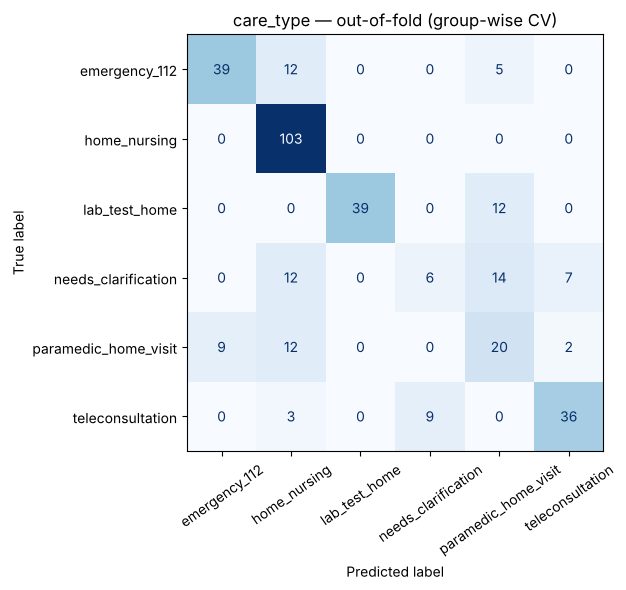

In [7]:
oof_proba = cross_val_predict(make_pipeline(BEST_C), X, y, cv=cv_grp, groups=g, method="predict_proba")
classes = np.array(sorted(set(y)))
oof_pred = classes[oof_proba.argmax(1)]

print(classification_report(y, oof_pred, digits=3))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y, oof_pred, labels=classes), display_labels=classes).plot(
    ax=ax, xticks_rotation=35, colorbar=False, cmap="Blues")
ax.set_title("care_type — out-of-fold (group-wise CV)")
plt.tight_layout(); fig.savefig(ART_DIR / "confusion_matrix.png", dpi=130); plt.show()

### 3.4 Confidence threshold

Model ka max-probability kam ho (jaise `"mujhe kuch chahiye"`) toh guess karne ke bajaye **follow-up question** poochna behtar hai. Threshold out-of-fold predictions se chuna jaata hai: sabse chhota threshold jahan accept kiye gaye predictions ki accuracy ≥ 95% ho.

In [8]:
maxp = oof_proba.max(1); correct = (oof_pred == y)
rows = []
for th in np.arange(0.30, 0.81, 0.05):
    acc_mask = maxp >= th
    rows.append({"threshold": round(th, 2), "coverage": acc_mask.mean(),
                 "accuracy_on_accepted": correct[acc_mask].mean() if acc_mask.any() else np.nan})
thr_df = pd.DataFrame(rows).round(3); display(thr_df)
ok = thr_df[thr_df.accuracy_on_accepted >= 0.95]
CONF_THRESHOLD = float(ok.threshold.iloc[0]) if len(ok) else 0.45
print("CONF_THRESHOLD =", CONF_THRESHOLD)

,threshold,coverage,accuracy_on_accepted
0,0.30,0.968,0.739
1,0.35,0.918,0.763
2,0.40,0.832,0.806
3,0.45,0.726,0.870
4,0.50,0.688,0.885
5,0.55,0.588,0.890
6,0.60,0.497,0.911
7,0.65,0.462,0.930
8,0.70,0.362,0.935
9,0.75,0.335,0.939


CONF_THRESHOLD = 0.45


### 3.5 Urgency pipeline — CV

In [9]:
y_u = df.y_urg.values
p_u = cross_val_predict(make_pipeline(BEST_C), X, y_u, cv=cv_grp, groups=g)
print(classification_report(y_u, p_u, digits=3))

                     precision    recall  f1-score   support

          emergency      1.000     0.536     0.698        56
needs_clarification      0.556     0.128     0.208        39
           same_day      0.699     0.979     0.815       194
          scheduled      1.000     0.569     0.725        51

           accuracy                          0.747       340
          macro avg      0.814     0.553     0.612       340
       weighted avg      0.777     0.747     0.713       340



## 4. Final fit + save pipelines (`.pkl` = sirf model artifact)

In [10]:
care_pipe = make_pipeline(BEST_C).fit(X, df.y_care.values)
urg_pipe  = make_pipeline(BEST_C).fit(X, df.y_urg.values)

joblib.dump(care_pipe, ART_DIR / "care_type_pipeline.pkl", compress=3)
joblib.dump(urg_pipe,  ART_DIR / "urgency_pipeline.pkl",  compress=3)

meta = {
    "trained_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__,
    "best_C": BEST_C,
    "conf_threshold": CONF_THRESHOLD,
    "n_rows": int(len(df)), "n_unique_texts": int(df.group.nunique()),
    "care_type_classes": list(care_pipe.classes_),
    "urgency_classes": list(urg_pipe.classes_),
    "cv_group_accuracy": round(float(accuracy_score(y, oof_pred)), 4),
    "cv_group_macro_f1": round(float(f1_score(y, oof_pred, average="macro")), 4),
    "note": "Pickles are sklearn-version specific; load with the same sklearn version.",
}
(ART_DIR / "model_meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))

for p in sorted(ART_DIR.iterdir()):
    print(f"{p.name:30s} {p.stat().st_size/1024:8.1f} KB")

care_type_pipeline.pkl             66.0 KB
confusion_matrix.png               76.9 KB
model_meta.json                     0.6 KB
urgency_pipeline.pkl               52.4 KB


In [11]:
# Reload sanity: saved pipeline unseen sentences par
reloaded = joblib.load(ART_DIR / "care_type_pipeline.pkl")
tests = ["mujhe mummy ka insulin lagwana hai", "I need a blood test at home", "chest mein bahut dard hai",
         "ghar par bukhar check karne koi aa jaye", "need a doctor to review my x-ray report", "kuch chahiye"]
out = pd.DataFrame(reloaded.predict_proba(tests), columns=reloaded.classes_, index=tests).round(2)
out["pred"] = reloaded.predict(tests); display(out)

,emergency_112,home_nursing,lab_test_home,needs_clarification,paramedic_home_visit,teleconsultation,pred
mujhe mummy ka insulin lagwana hai,0.05,0.56,0.02,0.10,0.23,0.05,home_nursing
I need a blood test at home,0.02,0.05,0.81,0.08,0.02,0.02,lab_test_home
chest mein bahut dard hai,0.41,0.18,0.07,0.10,0.14,0.11,emergency_112
ghar par bukhar check karne koi aa jaye,0.03,0.09,0.04,0.05,0.76,0.02,paramedic_home_visit
need a doctor to review my x-ray report,0.01,0.02,0.01,0.04,0.01,0.92,teleconsultation
kuch chahiye,0.01,0.02,0.01,0.94,0.01,0.01,needs_clarification


## 5. Triage inference layer (`triage_logic.py`)

Model + **safety rules** saath mein:

1. **Red-flag rules** (chest pain, breathlessness, severe bleeding, collapse/unresponsive — English / Hindi / Hinglish) → seedha `emergency_112`, model se pooch bhi nahi.
2. Model ki emergency-probability `≥ 0.30` ho toh bhi escalate (safety-first; galat alarm sasta hai, miss mehenga).
3. Confidence `< conf_threshold` ya class `needs_clarification` → **follow-up question** (user ki language mein).
4. Warna model ka `care_type` + `urgency`.

In [12]:
%%writefile triage_logic.py
"""Triage inference: TF-IDF + LR pipelines (.pkl) + safety rules. No matching logic here."""
import json
import re
from functools import lru_cache
from pathlib import Path

import joblib

ART_DIR = Path(__file__).resolve().parent / "artifacts"
NEEDS_CLARIFICATION = "needs_clarification"
EMERGENCY = "emergency_112"
EMERGENCY_ESCALATE_P = 0.30        # model prob >= this -> treat as emergency (safety first)

RED_FLAG_PATTERNS = {
    "chest_pain": r"chest\s*pain|seene?\s*(?:me|mein|mai)\s*(?:\w+\s*)?dard|सीने\s*(?:में|मे)\s*(?:\S+\s*)?दर्द",
    "breathlessness": r"can'?t\s*breathe|cannot\s*breathe|breathless|short(?:ness)?\s*of\s*breath|"
                      r"saans?\s*nahi|sans\s*nahi|सा[ंँ]स\s*नही[ंं]?",
    "severe_bleeding": r"bleed|खून\s*(?:नहीं\s*)?(?:रुक|बह)|khoon\s*(?:nahi\s*)?(?:ruk|beh)",
    "unresponsive_collapse": r"collaps|unconscious|not\s*responding|response\s*nahi|jawab\s*nahi|behosh|"
                             r"gir\s*gay[ei]|गिर\s*गए|गिर\s*गई|जवाब\s*नहीं|बेहोश",
}
_RED_FLAG_RE = {k: re.compile(v, re.IGNORECASE) for k, v in RED_FLAG_PATTERNS.items()}

_HINGLISH_TOKENS = {
    "hai", "hain", "ghar", "ko", "ka", "ki", "ke", "pe", "par", "nahi", "chahiye", "karwana", "karwani",
    "karna", "karni", "aur", "se", "mein", "me", "papa", "mummy", "dadi", "dada", "dadaji", "wo", "wife",
    "ruk", "rahi", "rahe", "lagwana", "likha", "sakta", "koi", "kuch", "baat", "baare", "subah", "kal",
    "bukhar", "khansi", "saans", "dard", "bacche", "medicine", "ho", "hoon", "mujhe", "mera", "meri",
}

FOLLOW_UPS = {
    "English": "Happy to help. Could you tell me the main symptom or service you need "
               "(home visit, nursing, lab test, or teleconsult)?",
    "Hindi": "ज़रूर, मैं मदद करूँगा। कृपया बताइए कि मुख्य लक्षण या ज़रूरत क्या है "
             "(घर पर विज़िट, नर्सिंग, लैब टेस्ट या डॉक्टर से कंसल्ट)?",
    "Hinglish": "Zaroor, madad karunga. Please bataiye mukhya symptom ya service kya chahiye "
                "(home visit, nursing, lab test ya doctor consult)?",
}
EMERGENCY_MESSAGE = {
    "English": "This looks like an emergency. Call 112 immediately — do not wait for a home visit.",
    "Hindi": "यह आपातकालीन स्थिति लग रही है। तुरंत 112 पर कॉल करें — घर पर विज़िट का इंतज़ार न करें।",
    "Hinglish": "Yeh emergency lag rahi hai. Turant 112 par call karein — home visit ka wait na karein.",
}


@lru_cache(maxsize=1)
def load_models():
    care = joblib.load(ART_DIR / "care_type_pipeline.pkl")
    urg = joblib.load(ART_DIR / "urgency_pipeline.pkl")
    meta = json.loads((ART_DIR / "model_meta.json").read_text(encoding="utf-8"))
    return care, urg, meta


def normalize(text: str) -> str:
    return re.sub(r"\s+", " ", text.replace("’", "'").replace("‘", "'")).strip()


def detect_language(text: str) -> str:
    letters = [c for c in text if c.isalpha()]
    if not letters:
        return "English"
    deva = sum("ऀ" <= c <= "ॿ" for c in letters) / len(letters)
    if deva > 0.3:
        return "Hindi"
    toks = set(re.findall(r"[a-z']+", text.lower()))
    return "Hinglish" if toks & _HINGLISH_TOKENS else "English"


def detect_red_flags(text: str) -> list:
    return [name for name, rx in _RED_FLAG_RE.items() if rx.search(text)]


def triage(text: str) -> dict:
    care_pipe, urg_pipe, meta = load_models()
    clean = normalize(text)
    lang = detect_language(clean)
    flags = detect_red_flags(clean)

    care_p = dict(zip(care_pipe.classes_, care_pipe.predict_proba([clean])[0]))
    urg_p = dict(zip(urg_pipe.classes_, urg_pipe.predict_proba([clean])[0]))
    top_cls, top_p = max(care_p.items(), key=lambda kv: kv[1])
    thr = meta.get("conf_threshold", 0.45)

    if flags:
        care, urgency, source, conf = EMERGENCY, "emergency", "red_flag_rules", 1.0
        reasoning = f"Red-flag symptoms detected ({', '.join(flags)}); routed to emergency services, not home care."
    elif care_p.get(EMERGENCY, 0) >= EMERGENCY_ESCALATE_P or urg_p.get("emergency", 0) >= EMERGENCY_ESCALATE_P:
        care, urgency, source = EMERGENCY, "emergency", "model_escalation"
        conf = max(care_p.get(EMERGENCY, 0), urg_p.get("emergency", 0))
        reasoning = "Model flagged possible emergency; escalated as a precaution."
    elif top_cls == NEEDS_CLARIFICATION or top_p < thr:
        care, urgency, source, conf = NEEDS_CLARIFICATION, None, "model", top_p
        reasoning = ("Intent underspecified — asking a follow-up before deciding care type."
                     if top_cls == NEEDS_CLARIFICATION else
                     f"Low model confidence ({top_p:.2f} < {thr}) — asking a follow-up instead of guessing.")
    else:
        care, source, conf = top_cls, "model", top_p
        u = max(urg_p.items(), key=lambda kv: kv[1])[0]
        urgency = None if u == NEEDS_CLARIFICATION else u
        reasoning = f"Model predicted {care} (p={top_p:.2f}); urgency assessed as {urgency}."

    return {
        "care_type": care,
        "urgency": urgency,
        "red_flags": flags,
        "confidence": round(float(conf), 3),
        "source": source,
        "detected_language": lang,
        "follow_up_question": FOLLOW_UPS[lang] if care == NEEDS_CLARIFICATION else None,
        "emergency_message": EMERGENCY_MESSAGE[lang] if care == EMERGENCY else None,
        "reasoning": reasoning,
        "probabilities": {k: round(float(v), 3) for k, v in sorted(care_p.items(), key=lambda kv: -kv[1])},
    }

Writing triage_logic.py


In [13]:
for m in ("triage_logic", "matcher", "app"): sys.modules.pop(m, None)
importlib.invalidate_caches()
if str(BASE) not in sys.path: sys.path.insert(0, str(BASE))
import triage_logic

samples = ["Doctor prescribed an injection, can someone come home",
           "papa ko severe chest pain hai saans nahi aa rahi",
           "वो अचानक गिर गए और जवाब नहीं दे रहे",
           "doctor chahiye",
           "कल सुबह शुगर टेस्ट घर पर",
           "mummy ka bp check karwana hai ghar pe",
           "need second opinion on my son's prescription"]
res = pd.DataFrame([{**{"text": s}, **{k: v for k, v in triage_logic.triage(s).items()
                    if k in ("care_type", "urgency", "red_flags", "confidence", "source", "detected_language")}} for s in samples])
display(res)

,text,care_type,urgency,red_flags,confidence,source,detected_language
0,"Doctor prescribed an injection, can someone come home",home_nursing,same_day,[],0.986,model,English
1,papa ko severe chest pain hai saans nahi aa rahi,emergency_112,emergency,"[chest_pain, breathlessness]",1.000,red_flag_rules,Hinglish
2,वो अचानक गिर गए और जवाब नहीं दे रहे,emergency_112,emergency,[unresponsive_collapse],1.000,red_flag_rules,Hindi
3,doctor chahiye,needs_clarification,NaN,[],0.989,model,Hinglish
4,कल सुबह शुगर टेस्ट घर पर,lab_test_home,scheduled,[],0.985,model,Hindi
5,mummy ka bp check karwana hai ghar pe,paramedic_home_visit,same_day,[],0.980,model,Hinglish
6,need second opinion on my son's prescription,teleconsultation,same_day,[],0.981,model,English


### 5.1 Out-of-fold check of the full triage logic (rules + model)

In [14]:
# Rules deterministic hain, isliye poore dataset par red-flag rules ka recall seedha napa ja sakta hai.
emerg = df[df.y_care == "emergency_112"]
rule_hit = emerg.text.apply(lambda t: len(triage_logic.detect_red_flags(triage_logic.normalize(t))) > 0)
non_emerg = df[df.y_care != "emergency_112"]
false_alarm = non_emerg.text.apply(lambda t: len(triage_logic.detect_red_flags(triage_logic.normalize(t))) > 0)
print(f"Red-flag rules recall on emergency rows : {rule_hit.mean():.1%}  ({rule_hit.sum()}/{len(emerg)})")
print(f"Red-flag rules false alarms on others   : {false_alarm.mean():.1%}  ({false_alarm.sum()}/{len(non_emerg)})")

Red-flag rules recall on emergency rows : 100.0%  (56/56)
Red-flag rules false alarms on others   : 0.0%  (0/284)


## 6. Rule-based caregiver matching (`matcher.py`)

ML nahi — caregiver CSV par seedhe rules. Do stage: **hard filters** (kaun eligible hai) → **weighted score** (kaun best hai).

**Hard filters**

| Filter | Rule |
|---|---|
| active | `active == True` |
| role | `teleconsultation→doctor`, `home_nursing / paramedic_home_visit→medic`, `lab_test_home→phlebotomist` |
| skill | nursing: text se (`injection`→`injection_im`, `IV/drip`→`injection_iv`, dressing/bedsore/post-op→`wound_dressing`, catheter, nebulizer); paramedic visit → `vitals_monitoring`; lab → `sample_collection` |
| radius | home visit mein `distance(haversine) ≤ max_radius_km`; **teleconsult mein radius lagu nahi** |
| time (optional) | `request_time` diya ho toh `free_from ≤ t ≤ free_until` |

**Score (0–1)** — weights eligible components par normalize hote hain

`proximity .35 · rating .25 · experience .10 · preferred-skills .10 · language .10 · tier .10 (sirf medic) · gender-pref .05 (agar maanga ho)`

Teleconsult mein proximity nahi, toh woh weight baaki mein baant jaata hai.

In [15]:
%%writefile matcher.py
"""Rule-based caregiver matching & ranking. Reads caregivers.csv; no ML, no pickles."""
import re
from pathlib import Path

import numpy as np
import pandas as pd

HOME_VISIT = {"home_nursing", "paramedic_home_visit", "lab_test_home"}
MATCHABLE = HOME_VISIT | {"teleconsultation"}
ROLE_FOR = {
    "teleconsultation": "doctor",
    "home_nursing": "medic",
    "paramedic_home_visit": "medic",
    "lab_test_home": "phlebotomist",
}
TIER_SCORE = {"base": 0.25, "standard": 0.50, "advanced": 0.75, "expert": 1.00}

_IV = re.compile(r"\biv\b|drip|saline|ड्रिप", re.I)
_INJ = re.compile(r"inject|इंजेक्शन|insulin|इंसुलिन|\bim\b", re.I)
_DRESS = re.compile(r"dressing|bedsore|wound|post[- ]?op|operation|surgery|bandage|घाव|पट्टी|ड्रेसिंग|ऑपरेशन", re.I)
_CATH = re.compile(r"catheter|कैथेटर", re.I)
_NEB = re.compile(r"nebuli[sz]|नेबुला", re.I)


def required_skills(text: str, care_type: str):
    """Returns (hard_required_skills, preferred_skills)."""
    t = text or ""
    if care_type == "teleconsultation":
        return ["teleconsultation"], ["report_review", "prescription"]
    if care_type == "lab_test_home":
        return ["sample_collection"], ["home_phlebotomy"]
    if care_type == "paramedic_home_visit":
        return ["vitals_monitoring"], ["bp_sugar_check", "elderly_care"]
    if care_type == "home_nursing":
        hard = []
        if _IV.search(t): hard.append("injection_iv")
        elif _INJ.search(t): hard.append("injection_im")
        if _DRESS.search(t): hard.append("wound_dressing")
        if _CATH.search(t): hard.append("catheter_care")
        if _NEB.search(t): hard.append("nebulization")
        return hard, ["elderly_care", "post_surgical_care"]
    return [], []


def load_caregivers(path) -> pd.DataFrame:
    df = pd.read_csv(path)
    df["active"] = df["active"].astype(str).str.strip().str.lower().isin(["true", "1", "yes"])
    df["skills_list"] = df["skills"].fillna("").str.split(";").apply(lambda xs: [x.strip() for x in xs if x.strip()])
    df["lang_list"] = df["languages"].fillna("").str.split(";").apply(lambda xs: [x.strip() for x in xs if x.strip()])
    df["tier"] = df["tier"].fillna("")
    return df


def haversine_km(lat1, lng1, lat2, lng2):
    p = np.pi / 180
    a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lng2 - lng1) * p / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(a))


def _to_min(hhmm: str) -> int:
    m = re.fullmatch(r"(\d{1,2}):(\d{2})", str(hhmm).strip())
    if not m or int(m[1]) > 23 or int(m[2]) > 59:
        raise ValueError(f"request_time must be HH:MM (24h), got {hhmm!r}")
    return int(m[1]) * 60 + int(m[2])


def match_caregivers(caregivers: pd.DataFrame, care_type: str, text: str, lat: float, lng: float,
                     language: str = "Hindi", request_time: str = None, preferred_gender: str = None,
                     top_k: int = 3) -> dict:
    if care_type not in MATCHABLE:
        raise ValueError(f"care_type {care_type!r} is not matchable")
    role = ROLE_FOR[care_type]
    hard, preferred = required_skills(text, care_type)
    home = care_type in HOME_VISIT
    funnel = {"total": len(caregivers)}

    cc = caregivers[caregivers.active & (caregivers.role == role)].copy()
    funnel["active_and_role"] = len(cc)
    if hard:
        cc = cc[cc.skills_list.apply(lambda s: all(k in s for k in hard))]
    funnel["has_required_skills"] = len(cc)

    cc["distance_km"] = haversine_km(lat, lng, cc.base_lat.values, cc.base_lng.values) if len(cc) else []
    if home:
        cc = cc[cc.distance_km <= cc.max_radius_km]
        funnel["within_radius"] = len(cc)
    if request_time:
        t = _to_min(request_time)
        cc = cc[cc.apply(lambda r: _to_min(r.free_from) <= t <= _to_min(r.free_until), axis=1)]
        funnel["available_at_time"] = len(cc)

    result = {"care_type": care_type, "role_required": role, "required_skills": hard,
              "preferred_skills": preferred, "candidates": [], "top_score": None, "funnel": funnel,
              "message": None}
    if cc.empty:
        stage = next((k for k, v in list(funnel.items())[1:] if v == 0), "unknown")
        why = {"active_and_role": "no active caregiver with this role",
               "has_required_skills": "no active caregiver has the required skill(s)",
               "within_radius": "no eligible caregiver covers this location",
               "available_at_time": "no eligible caregiver is free at the requested time"}.get(stage, "no match")
        result["message"] = f"No caregiver available: {why}."
        return result

    need_lang = "English" if language == "English" else "Hindi"
    weights = {"rating": 0.25, "experience": 0.10, "skills": 0.10, "language": 0.10}
    if home: weights["proximity"] = 0.35
    else:    weights["rating"] += 0.15; weights["experience"] += 0.10; weights["language"] += 0.10
    if role == "medic": weights["tier"] = 0.10
    if preferred_gender: weights["gender"] = 0.05

    def comp(r):
        c = {
            "rating": float(np.clip((r.rating - 3.5) / 1.5, 0, 1)),
            "experience": min(r.experience_years / 15, 1.0),
            "skills": (sum(k in r.skills_list for k in preferred) / len(preferred)) if preferred else 1.0,
            "language": 1.0 if need_lang in r.lang_list else 0.0,
        }
        if "proximity" in weights: c["proximity"] = max(0.0, 1 - r.distance_km / r.max_radius_km)
        if "tier" in weights: c["tier"] = TIER_SCORE.get(r.tier, 0.0)
        if "gender" in weights: c["gender"] = 1.0 if r.gender == preferred_gender else 0.0
        return c

    wsum = sum(weights.values())
    rows = []
    for _, r in cc.iterrows():
        c = comp(r)
        score = sum(weights[k] * c[k] for k in weights) / wsum
        rows.append((score, r, c))
    rows.sort(key=lambda x: (-round(x[0], 4), x[1].distance_km, -x[1].rating))

    for score, r, c in rows[:top_k]:
        result["candidates"].append({
            "caregiver_id": r.caregiver_id, "name": r["name"], "role": r.role,
            "qualification": r.qualification, "gender": r.gender,
            "languages": r.lang_list, "skills": r.skills_list,
            "distance_km": round(float(r.distance_km), 2), "rating": float(r.rating),
            "experience_years": int(r.experience_years), "tier": r.tier or None,
            "free_window": f"{r.free_from}-{r.free_until}",
            "score": round(float(score), 3),
            "score_breakdown": {k: round(v, 3) for k, v in c.items()},
        })
    result["top_score"] = result["candidates"][0]["score"]
    return result

Writing matcher.py


In [16]:
import matcher
caregivers = matcher.load_caregivers(DATA_DIR / "caregivers.csv")

r = matcher.match_caregivers(caregivers, "home_nursing", "Insulin injection help needed for elderly father",
                             lat=28.5947, lng=77.0508, language="English")
print("required:", r["required_skills"], "| funnel:", r["funnel"])
display(pd.DataFrame(r["candidates"])[["caregiver_id", "name", "tier", "distance_km", "rating", "experience_years", "free_window", "score"]])

print("\nTeleconsult (radius lagu nahi):")
r = matcher.match_caregivers(caregivers, "teleconsultation", "Want to talk to a doctor about my reports", 28.46, 77.09, "Hinglish")
display(pd.DataFrame(r["candidates"])[["caregiver_id", "name", "distance_km", "rating", "experience_years", "free_window", "score"]])

print("\nKoi match nahi (Greater Noida se door, lab test):")
print(matcher.match_caregivers(caregivers, "lab_test_home", "cbc test", 28.75, 77.39, "English")["message"])

required: ['injection_im'] | funnel: {'total': 60, 'active_and_role': 23, 'has_required_skills': 10, 'within_radius': 2}


,caregiver_id,name,tier,distance_km,rating,experience_years,free_window,score
0,CG_019,Rahul Verma,standard,1.21,4.2,18,11:00-19:00,0.606
1,CG_014,Ankit Gupta,standard,4.88,4.8,6,08:00-11:00,0.564



Teleconsult (radius lagu nahi):


,caregiver_id,name,distance_km,rating,experience_years,free_window,score
0,CG_030,Pawan Singh,32.03,5.0,18,10:00-16:00,1.000
1,CG_029,Meena Saini,20.44,4.8,14,13:00-18:00,0.926
2,CG_021,Rekha Gupta,14.01,4.9,9,13:00-16:00,0.881



Koi match nahi (Greater Noida se door, lab test):
No caregiver available: no eligible caregiver covers this location.


### 6.1 Matcher ko dataset ke labeled matches se validate karna

Dataset ka `matched_caregiver_ids` ek reference hai. Check karte hain:

* **Eligibility:** jo caregivers dataset ne match kiye woh hamare hard filters ke andar aate hain? (rules sahi hain ya nahi)
* **Empty-agreement:** dataset mein jahan koi match nahi, wahan hamara matcher bhi khaali deta hai?
* **Ranking agreement:** top-1 aur top-3 overlap — yeh sirf informational hai, kyunki ranking ka exact formula dataset mein nahi diya.

In [17]:
lab = df[df.care_type.isin(matcher.MATCHABLE)].copy()
recs = []
for _, r in lab.iterrows():
    ref = r.matched_caregiver_ids.split(";") if isinstance(r.matched_caregiver_ids, str) else []
    out = matcher.match_caregivers(caregivers, r.care_type, r.text, r.lat, r.lng, r.detected_language, top_k=3)
    mine = [c["caregiver_id"] for c in out["candidates"]]
    # full eligible set (top_k bada karke) — eligibility check ke liye
    elig = [c["caregiver_id"] for c in matcher.match_caregivers(caregivers, r.care_type, r.text, r.lat, r.lng,
                                                              r.detected_language, top_k=100)["candidates"]]
    recs.append({"care_type": r.care_type, "ref_n": len(ref), "mine_n": len(elig),
                 "ref_subset_of_eligible": set(ref) <= set(elig),
                 "empty_agree": (len(ref) == 0) == (len(elig) == 0),
                 "top1_agree": bool(ref and mine and ref[0] == mine[0]),
                 "overlap_at3": len(set(ref) & set(mine)) / max(len(ref), 1) if ref else np.nan})
ev = pd.DataFrame(recs)
summary = ev.groupby("care_type").agg(rows=("care_type", "size"),
                                      ref_subset_of_eligible=("ref_subset_of_eligible", "mean"),
                                      empty_agree=("empty_agree", "mean"),
                                      top1_agree=("top1_agree", "mean"),
                                      overlap_at3=("overlap_at3", "mean")).round(3)
display(summary)
print("Overall eligibility agreement:", ev.ref_subset_of_eligible.mean().round(3),
      "| empty/non-empty agreement:", ev.empty_agree.mean().round(3))

,rows,ref_subset_of_eligible,empty_agree,top1_agree,overlap_at3
care_type,,,,,
home_nursing,103,1.0,1.0,0.602,0.963
lab_test_home,51,1.0,1.0,0.490,0.967
paramedic_home_visit,43,1.0,1.0,0.907,0.988
teleconsultation,48,1.0,1.0,0.000,0.569


Overall eligibility agreement: 1.0 | empty/non-empty agreement: 1.0


## 7. FastAPI — triage aur matching ko jodna (`app.py`)

| Endpoint | Kaam |
|---|---|
| `GET /health` | model + caregiver data loaded? |
| `POST /triage` | sirf text → care_type / urgency / red_flags / follow-up |
| `POST /match` | sirf matching (care_type + lat/lng) |
| `POST /triage-and-match` | **dono ek saath** — emergency ho toh 112, unclear ho toh follow-up, warna top-K caregivers |

`/triage-and-match` ka `action` field: `call_112` · `ask_follow_up` · `matched` · `no_caregiver_available`.

In [18]:
%%writefile app.py
"""FastAPI: connects triage_logic (TF-IDF+LR .pkl + rules) with matcher (rule-based, caregivers.csv)."""
import os
from contextlib import asynccontextmanager
from pathlib import Path
from typing import Literal, Optional

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

import matcher
import triage_logic

BASE = Path(__file__).resolve().parent
CAREGIVERS_CSV = Path(os.getenv("CAREGIVERS_CSV", BASE / "data" / "caregivers.csv"))
STATE: dict = {}


@asynccontextmanager
async def lifespan(app: FastAPI):
    triage_logic.load_models()                                   # .pkl artifacts
    STATE["caregivers"] = matcher.load_caregivers(CAREGIVERS_CSV)  # rule-based side
    yield
    STATE.clear()


app = FastAPI(title="Triage + Caregiver Matching API", version="1.0.0", lifespan=lifespan)

CareType = Literal["home_nursing", "paramedic_home_visit", "lab_test_home", "teleconsultation"]
Language = Literal["English", "Hindi", "Hinglish"]
HHMM = r"^\d{1,2}:\d{2}$"


class TriageRequest(BaseModel):
    text: str = Field(min_length=1, max_length=1000, examples=["papa ko insulin injection chahiye ghar pe"])


class MatchRequest(BaseModel):
    care_type: CareType
    text: str = Field("", max_length=1000)
    lat: float = Field(ge=-90, le=90)
    lng: float = Field(ge=-180, le=180)
    language: Language = "Hindi"
    request_time: Optional[str] = Field(None, pattern=HHMM, description="HH:MM, 24h")
    preferred_gender: Optional[Literal["M", "F"]] = None
    top_k: int = Field(3, ge=1, le=10)


class TriageAndMatchRequest(BaseModel):
    text: str = Field(min_length=1, max_length=1000)
    lat: float = Field(ge=-90, le=90)
    lng: float = Field(ge=-180, le=180)
    request_time: Optional[str] = Field(None, pattern=HHMM, description="HH:MM, 24h")
    preferred_gender: Optional[Literal["M", "F"]] = None
    top_k: int = Field(3, ge=1, le=10)


def _match(req_care_type, text, lat, lng, language, request_time, preferred_gender, top_k):
    try:
        return matcher.match_caregivers(STATE["caregivers"], req_care_type, text, lat, lng,
                                        language=language, request_time=request_time,
                                        preferred_gender=preferred_gender, top_k=top_k)
    except ValueError as e:
        raise HTTPException(status_code=422, detail=str(e))


@app.get("/health")
def health():
    _, _, meta = triage_logic.load_models()
    return {"status": "ok", "caregivers_loaded": len(STATE.get("caregivers", [])),
            "model_trained_at": meta["trained_at_utc"], "model_classes": meta["care_type_classes"]}


@app.post("/triage")
def triage_endpoint(req: TriageRequest):
    return triage_logic.triage(req.text)


@app.post("/match")
def match_endpoint(req: MatchRequest):
    return _match(req.care_type, req.text, req.lat, req.lng, req.language,
                  req.request_time, req.preferred_gender, req.top_k)


@app.post("/triage-and-match")
def triage_and_match(req: TriageAndMatchRequest):
    t = triage_logic.triage(req.text)
    ct = t["care_type"]
    if ct == triage_logic.EMERGENCY:
        return {"action": "call_112", "triage": t, "matching": None}
    if ct == triage_logic.NEEDS_CLARIFICATION:
        return {"action": "ask_follow_up", "triage": t, "matching": None}
    m = _match(ct, req.text, req.lat, req.lng, t["detected_language"],
               req.request_time, req.preferred_gender, req.top_k)
    return {"action": "matched" if m["candidates"] else "no_caregiver_available", "triage": t, "matching": m}

Writing app.py


In [19]:
(BASE / "requirements.txt").write_text(
    "fastapi>=0.110\nuvicorn[standard]>=0.29\npandas\nnumpy\njoblib\npydantic>=2\nhttpx\n"
    f"scikit-learn=={sklearn.__version__}   # .pkl isi version se load hota hai\n")
print((BASE / "requirements.txt").read_text())

fastapi>=0.110
uvicorn[standard]>=0.29
pandas
numpy
joblib
pydantic>=2
httpx
scikit-learn==1.9.1   # .pkl isi version se load hota hai



### 7.1 API test (`TestClient` — server chalaye bina, lifespan ke saath)

In [20]:
for m in ("triage_logic", "matcher", "app"): sys.modules.pop(m, None)
from fastapi.testclient import TestClient
import app as app_module

def show(title, resp):
    print(f"\n### {title}  -> HTTP {resp.status_code}")
    j = resp.json()
    if resp.status_code != 200: print(j); return
    if "action" in j:
        t = j["triage"]
        print("action     :", j["action"])
        print("triage     :", {k: t[k] for k in ("care_type", "urgency", "red_flags", "confidence", "source", "detected_language")})
        if t["follow_up_question"]: print("follow-up  :", t["follow_up_question"])
        if t["emergency_message"]:  print("emergency  :", t["emergency_message"])
        if j["matching"]:
            m = j["matching"]; print("required   :", m["required_skills"], "| funnel:", m["funnel"])
            for c in m["candidates"]: print(f"   {c['caregiver_id']} {c['name']:<14} {c['distance_km']:>5} km  rating {c['rating']}  score {c['score']}  {c['free_window']}")
            if m["message"]: print("message    :", m["message"])
    else:
        print(json.dumps(j, ensure_ascii=False)[:600])

with TestClient(app_module.app) as client:
    show("health", client.get("/health"))
    show("injection, Dwarka side (Hinglish)", client.post("/triage-and-match", json={"text": "papa ko insulin injection chahiye ghar pe", "lat": 28.5947, "lng": 77.0508}))
    show("emergency (Hindi)", client.post("/triage-and-match", json={"text": "पापा को तेज सीने में दर्द है और सांस नहीं आ रही", "lat": 28.5, "lng": 77.2}))
    show("vague -> follow-up", client.post("/triage-and-match", json={"text": "doctor chahiye", "lat": 28.5, "lng": 77.2}))
    show("lab test, request_time 15:00 (caregiver free 14-21)", client.post("/triage-and-match", json={"text": "Need blood sugar test at home tomorrow morning", "lat": 28.5807, "lng": 77.0491, "request_time": "15:00"}))
    show("lab test, request_time 10:00 (nobody free)", client.post("/triage-and-match", json={"text": "Need blood sugar test at home tomorrow morning", "lat": 28.5807, "lng": 77.0491, "request_time": "10:00"}))
    show("lab test far away -> no caregiver", client.post("/triage-and-match", json={"text": "cbc aur thyroid test ghar se sample lekar", "lat": 28.75, "lng": 77.39}))
    show("teleconsult, female doctor preferred", client.post("/triage-and-match", json={"text": "Want to talk to a doctor about my reports", "lat": 28.46, "lng": 77.09, "preferred_gender": "F"}))
    show("/match direct", client.post("/match", json={"care_type": "paramedic_home_visit", "text": "fever", "lat": 28.6373, "lng": 77.3581, "language": "English", "top_k": 2}))
    show("validation error (bad lat)", client.post("/triage-and-match", json={"text": "hi", "lat": 999, "lng": 77}))
    show("validation error (bad time)", client.post("/match", json={"care_type": "lab_test_home", "lat": 28.5, "lng": 77.2, "request_time": "25:99"}))


### health  -> HTTP 200
{"status": "ok", "caregivers_loaded": 60, "model_trained_at": "2026-10-24T10:12:31+00:00", "model_classes": ["emergency_112", "home_nursing", "lab_test_home", "needs_clarification", "paramedic_home_visit", "teleconsultation"]}

### injection, Dwarka side (Hinglish)  -> HTTP 200
action     : matched
triage     : {'care_type': 'home_nursing', 'urgency': 'same_day', 'red_flags': [], 'confidence': 0.981, 'source': 'model', 'detected_language': 'Hinglish'}
required   : ['injection_im'] | funnel: {'total': 60, 'active_and_role': 23, 'has_required_skills': 10, 'within_radius': 2}
   CG_019 Rahul Verma     1.21 km  rating 4.2  score 0.706  11:00-19:00
   CG_014 Ankit Gupta     4.88 km  rating 4.8  score 0.664  08:00-11:00

### emergency (Hindi)  -> HTTP 200
action     : call_112
triage     : {'care_type': 'emergency_112', 'urgency': 'emergency', 'red_flags': ['chest_pain', 'breathlessness'], 'confidence': 1.0, 'source': 'red_flag_rules', 'detected_language': 'Hindi'}
e

## 8. Chalane ka tareeka

```bash
# project folder mein (notebook, app.py, matcher.py, triage_logic.py, artifacts/, data/ ek saath)
pip install -r requirements.txt
uvicorn app:app --host 0.0.0.0 --port 8000 --reload
# docs: http://localhost:8000/docs
```
```bash
curl -s localhost:8000/triage-and-match -H 'content-type: application/json' \
  -d '{"text":"papa ko insulin injection chahiye ghar pe","lat":28.5366,"lng":77.2550}'
```

Caregiver CSV kahin aur rakhni ho: `CAREGIVERS_CSV=/path/caregivers.csv uvicorn app:app`.

## 9. Limitations (seedhi baat)

* **Sirf ~65 unique training sentences** hain. Honest group-wise CV score ~**71% accuracy / 0.65 macro-F1** hai (random split ka ~99% leakage hai). Kamzor jagah: `needs_clarification` recall (~15%) aur `paramedic_home_visit` precision (~39%) — naye paraphrases par yeh classes confuse hoti hain. Real user logs se retrain karna sabse bada upgrade hai (notebook dobara chalao, `.pkl` badal jaayega).
* Isiliye **safety-net**: red-flag rules + emergency escalation threshold + low-confidence par follow-up. Yeh rules ek **medical triage ka substitute nahi** hain — emergency keywords ki list clinical review se guzarni chahiye.
* Red-flag regex "bleeding" jaise shabd par bhi trigger karta hai (jaise "gums bleeding") — safety ke liye jaan-boojh kar sensitive rakha hai.
* Matcher ka ranking formula (weights) hamara design hai; dataset ka exact ranking formula available nahi tha, isliye sirf **eligibility** 1:1 match hoti hai (section 6.1), ranking overlap approximate hai.
* `.pkl` sklearn **version-specific** hai (`requirements.txt` mein pinned). Untrusted `.pkl` kabhi load na karein.
* `request_time` abhi sirf same-day window check karta hai (booking calendar / conflicts nahi).